# 145 · Logging, alerting and rollback: a canary deployment with a sequential stopping rule

In [1]:
import os, json, time, numpy as np, matplotlib.pyplot as plt
from scipy.stats import beta
from vlacourse import TableTop, ExpertPolicy

class NoisyExpert(ExpertPolicy):
    def __init__(self, env, sigma, seed=0):
        super().__init__(env, tol=8e-3); self.sigma, self.rng = sigma, np.random.default_rng(seed)   # noisy hands never settle within 1 mm
    def act(self, obs):
        a = super().act(obs); a[:3] += self.rng.normal(0, self.sigma, 3); return a

class EpisodeLogger:
    def __init__(self, path):
        self.path = path; open(path, "w").close()
    def log(self, **kw):
        with open(self.path, "a") as f:
            f.write(json.dumps(kw) + "\n")

def run_episode(env, pol, seed):
    obs = env.reset(seed=seed); pol.reset(); done, t0 = False, time.time()
    while not done:
        obs, _, done, info = env.step(pol.act(obs))
    return dict(success=bool(info["success"]), steps=env.t, task=env.task["type"], wall=time.time() - t0)

def prob_worse(k_new, n_new, k_old, n_old, samples=20000, rng=np.random.default_rng(0)):
    """Bayesian A/B: P(p_new < p_old) under Beta(1+k, 1+n-k) posteriors."""
    return float((beta.rvs(1 + k_new, 1 + n_new - k_new, size=samples, random_state=rng) < beta.rvs(1 + k_old, 1 + n_old - k_old, size=samples, random_state=rng)).mean())

In [2]:
env = TableTop(cameras=(), seed=0)
current, candidate = NoisyExpert(env, 0.004, seed=1), NoisyExpert(env, 0.012, seed=2)
os.makedirs("logs", exist_ok=True)
log = EpisodeLogger("logs/canary.jsonl")
k = {"current": 0, "candidate": 0}; n = {"current": 0, "candidate": 0}; history, decision = [], None
for ep in range(80):
    arm = "candidate" if ep % 5 == 0 else "current"
    r = run_episode(env, candidate if arm == "candidate" else current, 5000 + ep)
    k[arm] += r["success"]; n[arm] += 1; log.log(episode=ep, arm=arm, **r)
    if n["candidate"] >= 5:
        pw = prob_worse(k["candidate"], n["candidate"], k["current"], n["current"]); history.append((ep, pw))
        if pw > 0.95 and decision is None:
            decision = (ep, "ROLLBACK: candidate worse than current with >95% posterior probability")
print(decision or "no rollback triggered")
print({a: f"{k[a]}/{n[a]}" for a in k})

(20, 'ROLLBACK: candidate worse than current with >95% posterior probability')
{'current': '64/64', 'candidate': '7/16'}


           success       steps  episodes
arm                                     
candidate   0.4375  178.187500        16
current     1.0000   41.546875        64


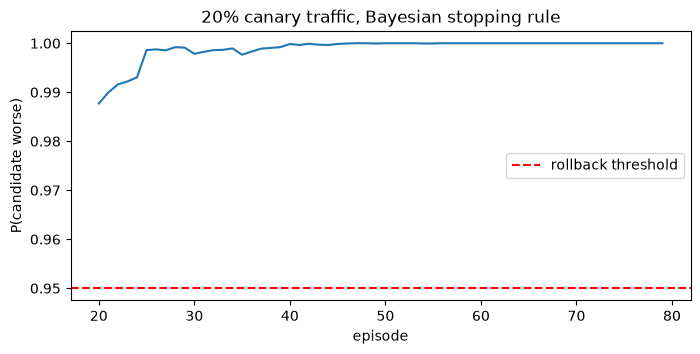

In [3]:
import pandas as pd
df = pd.read_json("logs/canary.jsonl", lines=True)
print(df.groupby("arm").agg(success=("success", "mean"), steps=("steps", "mean"), episodes=("episode", "count")))
h = np.array(history)
plt.figure(figsize=(8, 3.5)); plt.plot(h[:, 0], h[:, 1]); plt.axhline(0.95, c="r", ls="--", label="rollback threshold")
plt.xlabel("episode"); plt.ylabel("P(candidate worse)"); plt.legend(); plt.title("20% canary traffic, Bayesian stopping rule"); plt.show()